# Experiment 2 — Emotion variation in speaker representations

RAVDESS speech is used to examine how emotional changes affect speaker embeddings and verification with frozen ECAPA-TDNN and WavLM Large.


## Environment

Install the speech-model and analysis dependencies.


In [ ]:
import sys, subprocess, shutil, importlib, importlib.metadata as metadata
from packaging.version import Version

PINS = {
    "torch": "2.6.0", "torchaudio": "2.6.0", "torchvision": "0.21.0",
    "transformers": "4.49.0", "speechbrain": "1.0.3", "huggingface-hub": "0.29.3",
    "numpy": "2.1.3", "pandas": "2.2.3", "scipy": "1.15.2", "scikit-learn": "1.6.1",
    "matplotlib": "3.10.1", "soundfile": "0.13.1", "tqdm": "4.67.1",
    "nbformat": "5.10.4", "ipywidgets": "8.1.5",
}

def install_notebook_dependencies(pins, *, python_executable, python_version,
                                  loaded_modules, installed_version, run_pip, has_cuda_runtime):
    if not ((3, 10) <= tuple(python_version) <= (3, 13)):
        raise RuntimeError("Use a Colab Python 3.10–3.13 runtime for this environment.")
    requested = dict(pins)
    module_names = {"scikit-learn": "sklearn", "huggingface-hub": "huggingface_hub"}

    def version_on_disk(name):
        try:
            return installed_version(name).split("+")[0]
        except metadata.PackageNotFoundError:
            return None

    loaded, loaded_full = {}, {}
    for name in requested:
        module = loaded_modules.get(module_names.get(name, name))
        if module is not None:
            version = getattr(module, "__version__", None) or version_on_disk(name)
            if version is not None:
                loaded[name] = str(version).split("+")[0]
                loaded_full[name] = str(version)
    numpy_version = loaded.get("numpy")
    if numpy_version and Version("1.26.4") <= Version(numpy_version) < Version("2.3"):
        requested["numpy"] = numpy_version
        print(f"Keeping Colab's loaded NumPy {numpy_version} (compatible).")

    trio = ("torch", "torchaudio", "torchvision")
    wheel_index = "https://download.pytorch.org/whl/" + ("cu124" if has_cuda_runtime else "cpu")
    torch_cpu_build_on_gpu = (has_cuda_runtime and version_on_disk("torch") is not None
                              and "+cpu" in installed_version("torch"))
    if any(version_on_disk(name) != requested[name] for name in trio) or torch_cpu_build_on_gpu:
        run_pip([python_executable, "-m", "pip", "install", "--quiet", "--upgrade"] +
                [f"{name}=={requested[name]}" for name in trio] + ["--index-url", wheel_index])
    run_pip([python_executable, "-m", "pip", "install", "--quiet", "--upgrade"] +
            [f"{name}=={version}" for name, version in requested.items() if name not in trio])
    importlib.invalidate_caches()

    unresolved = [name for name, version in requested.items() if version_on_disk(name) != version]
    if unresolved:
        raise RuntimeError(f"Installation did not produce requested versions for {unresolved}; inspect pip output above.")
    changed = [name for name, version in loaded.items() if version_on_disk(name) != version
               or (name in trio and installed_version(name) != loaded_full[name])]
    if changed:
        raise RuntimeError("Setup finished installing dependencies, but updated libraries already loaded in memory: "
                           + ", ".join(changed) + ". Choose Runtime → Restart session, then Run all. "
                           "Installation is complete; the next setup run will use the installed versions.")
    print("Dependencies ready. Continue with the next cell.")
    return requested

PINS = install_notebook_dependencies(
    PINS, python_executable=sys.executable, python_version=sys.version_info[:2],
    loaded_modules=sys.modules, installed_version=metadata.version,
    run_pip=subprocess.check_call, has_cuda_runtime=bool(shutil.which("nvidia-smi")))

Keeping Colab's loaded NumPy 2.1.3 (compatible).
Dependencies ready. Continue with the next cell.


In [ ]:
import os, re, json, hashlib, zipfile, gc, warnings, math, itertools, platform, shutil
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from collections import Counter
from contextlib import nullcontext
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import soundfile as sf
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch
import torchaudio
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Markdown, Audio
from huggingface_hub import HfApi, snapshot_download
from transformers import WavLMModel, Wav2Vec2FeatureExtractor
from speechbrain.inference.classifiers import EncoderClassifier
from speechbrain.utils.fetching import LocalStrategy
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "ps.fonttype": 42})

DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for _speechbrain_save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for _speechbrain_load
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for load
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for _save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for _recover


## Configuration

Choose the dataset subset, pretrained models, and evaluation settings.


In [ ]:
MODE = "pilot"
SEED = 2025
DATASET_DIR_OVERRIDE = None
COPY_AUDIO_TO_LOCAL = True
STRICT_DATASET = True
BATCH_SIZE = 2
USE_MIXED_PRECISION = False
PLAY_AUDIO = False
MODEL_IDS = {"ecapa": "speechbrain/spkrec-ecapa-voxceleb", "wavlm": "microsoft/wavlm-large"}
MODEL_CACHE_DIR = Path("/content/pretrained_models")
MODEL_REVISION_OVERRIDES = {}
MODE_SPECS = {
    "smoke": {"actors": 6, "sentences": [1], "intensities": [1], "bootstrap": 50},
    "pilot": {"actors": 24, "sentences": [1], "intensities": [1], "bootstrap": 300},
    "full": {"actors": 24, "sentences": [1, 2], "intensities": [1, 2], "bootstrap": 1000},
}
assert MODE in MODE_SPECS
SPEC = MODE_SPECS[MODE]
N_BOOTSTRAP = SPEC["bootstrap"]
SAMPLE_RATE = 16000
EMOTIONS = {1: "neutral", 2: "calm", 3: "happy", 4: "sad", 5: "angry",
            6: "fearful", 7: "disgust", 8: "surprised"}
EMOTION_ORDER = list(EMOTIONS.values())
CACHE_SCHEMA = "ravdess-embeddings-v1"
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Mode={MODE}, device={DEVICE}, seed={SEED}, bootstrap draws={N_BOOTSTRAP}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("CPU mode: all models remain supported; WavLM Large inference can take a long time.")

Mode=pilot, device=cuda, seed=2025, bootstrap draws=300
NVIDIA L4


## RAVDESS dataset

Locate audio, parse filename labels, and validate recording metadata.


In [ ]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def json_write(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, default=str, allow_nan=False))
    temp.replace(path)

PRUNED_DIRS = {"experiment_results", "feature_cache", "cache", "__MACOSX", "runs"}
def walk_files(root, suffix):
    found = []
    for directory, dirs, files in os.walk(root, followlinks=False):
        dirs[:] = sorted(d for d in dirs if d not in PRUNED_DIRS and not d.startswith("."))
        found.extend(Path(directory) / f for f in sorted(files)
                     if not f.startswith(".") and f.lower().endswith(suffix))
    return sorted(found)

def locate_dataset(my_drive, override=None):
    expected = Path(my_drive) / "RAVDESS"
    if override is not None:
        root = Path(override)
        if root.is_dir():
            return root
        raise FileNotFoundError(f"Override missing: {root}. Expected default: {expected}")
    if expected.is_dir():
        return expected
    matches = []
    for directory, dirs, _ in os.walk(my_drive, followlinks=False):
        dirs[:] = sorted(d for d in dirs if not d.startswith(".") and d not in PRUNED_DIRS)
        for d in dirs[:]:
            if d.casefold() == "ravdess":
                matches.append(Path(directory) / d)
                dirs.remove(d)
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Expected existing dataset at {expected}. Found {len(matches)} alternatives: "
                            f"{matches}. Set DATASET_DIR_OVERRIDE if needed. No dataset will be downloaded.")

def parse_filename(path):
    match = re.fullmatch(r"(\d{2})-(\d{2})-(\d{2})-(\d{2})-(\d{2})-(\d{2})-(\d{2})\.wav",
                         Path(path).name, re.IGNORECASE)
    if not match:
        return None
    modality, vocal, emotion, intensity, sentence, repetition, actor = map(int, match.groups())
    if modality != 3 or vocal != 1:
        return None
    if not (emotion in EMOTIONS and intensity in (1, 2) and sentence in (1, 2)
            and repetition in (1, 2) and 1 <= actor <= 24 and not (emotion == 1 and intensity == 2)):
        raise ValueError(f"Invalid audio-speech metadata in {path}")
    return dict(uid=Path(path).name.lower(), path=str(path), actor=actor, emotion_id=emotion,
                emotion=EMOTIONS[emotion], intensity=intensity, sentence=sentence, repetition=repetition)

def audio_manifest(paths):
    rows, seen, skipped = [], {}, 0
    for path in paths:
        row = parse_filename(path)
        if row is None:
            skipped += 1
            continue
        if row["uid"] in seen:
            if sha256_file(path) != sha256_file(seen[row["uid"]]):
                raise ValueError(f"Conflicting copies of {row['uid']}; resolve duplicate recordings first.")
            continue
        seen[row["uid"]] = path
        rows.append(row)
    if not rows:
        raise FileNotFoundError("No valid RAVDESS audio-only speech WAV files found in the existing folder.")
    frame = pd.DataFrame(rows).sort_values("uid").reset_index(drop=True)
    return frame, skipped

def extract_speech_zip(archive, local_root):
    digest = sha256_file(archive)
    target = Path(local_root) / ("archive_" + digest[:16])
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        members = [m for m in z.infolist() if not m.is_dir() and m.filename.lower().endswith(".wav")
                   and "__MACOSX" not in PurePosixPath(m.filename).parts]
        for member in tqdm(members, desc="Extract existing Drive ZIP"):
            name = PurePosixPath(member.filename)
            if name.is_absolute() or ".." in name.parts or "\\" in member.filename:
                raise ValueError(f"Unsafe ZIP member: {member.filename}")
            if parse_filename(name.name) is None:
                continue
            dest = target.joinpath(*name.parts)
            dest.parent.mkdir(parents=True, exist_ok=True)
            with z.open(member) as source, open(dest, "wb") as out:
                shutil.copyfileobj(source, out)
    return target

def discover_audio(root, local_root):
    wavs = walk_files(root, ".wav")
    valid_wavs = [p for p in wavs if parse_filename(p) is not None]
    print(f"Audio discovery: {len(wavs)} WAV files, {len(wavs) - len(valid_wavs)} unrelated WAV files excluded.")
    frame = audio_manifest(valid_wavs)[0] if valid_wavs else None
    archives = [p for p in walk_files(root, ".zip") if p.name.lower() == "audio_speech_actors_01-24.zip"]
    if archives and (frame is None or len(frame) < 1440):
        if len(archives) > 1:
            hashes = {sha256_file(p) for p in archives}
            if len(hashes) != 1:
                raise ValueError(f"Multiple different speech archives: {archives}; set a more specific override.")
        extracted = extract_speech_zip(archives[0], local_root)
        frame, _ = audio_manifest(walk_files(extracted, ".wav"))
    if frame is None:
        raise FileNotFoundError(f"Expected WAV actor folders or Audio_Speech_Actors_01-24.zip under {root}. "
                                "Expected default: /content/drive/MyDrive/RAVDESS/. No download attempted.")
    return frame

def validate_dataset(frame, strict=True):
    expected = {(a, e, i, s, r) for a in range(1, 25) for e in EMOTIONS
                for i in ((1,) if e == 1 else (1, 2)) for s in (1, 2) for r in (1, 2)}
    actual = set(frame[["actor", "emotion_id", "intensity", "sentence", "repetition"]].itertuples(index=False, name=None))
    missing = expected - actual
    print(f"Dataset: {len(frame):,} unique speech files; {frame.actor.nunique()} actors; "
          f"{frame.emotion.nunique()} emotions; missing design cells={len(missing)}")
    display(pd.crosstab(frame.emotion, frame.intensity).reindex(EMOTION_ORDER).fillna(0).astype(int))
    display(frame.groupby("actor").size().rename("files_per_actor").to_frame().T)
    if actual - expected or (strict and missing):
        raise ValueError(f"Incomplete/unexpected speech design. Expected 24 actors and 1,440 files. "
                         f"First missing cells: {sorted(missing)[:8]}. Check your existing Drive folder.")
    return {"files": len(frame), "actors": int(frame.actor.nunique()),
            "emotions": int(frame.emotion.nunique()), "missing_design_cells": len(missing)}

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
DATA_ROOT = locate_dataset(Path("/content/drive/MyDrive"), DATASET_DIR_OVERRIDE)
RESULT_ROOT = DATA_ROOT / "experiment_results"
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
OUT_DIR = RESULT_ROOT / "runs" / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_ROOT = Path("/content/RAVDESS")
all_audio = discover_audio(DATA_ROOT, LOCAL_ROOT)
dataset_summary = validate_dataset(all_audio, STRICT_DATASET)
print("Dataset folder:", DATA_ROOT)
print("Run outputs:", OUT_DIR)

Mounted at /content/drive
Audio discovery: 1462 WAV files, 22 unrelated WAV files excluded.
Dataset: 1,440 unique speech files; 24 actors; 8 emotions; missing design cells=0


intensity,1,2
emotion,,
neutral,96,0
calm,96,96
happy,96,96
sad,96,96
angry,96,96
fearful,96,96
disgust,96,96
surprised,96,96


actor,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
files_per_actor,60,60,60,60,60,60,60,60,60,60,...,60,60,60,60,60,60,60,60,60,60


Dataset folder: /content/drive/MyDrive/RAVDESS
Run outputs: /content/drive/MyDrive/RAVDESS/experiment_results/runs/20261114T211142902790Z_pilot


## Actor splits and verification pairs

Create actor-disjoint partitions and same-/cross-emotion speaker trials.


In [ ]:
def choose_and_split(frame, spec, seed):
    rng = np.random.default_rng(seed)
    available = sorted(frame.actor.unique())
    odd = rng.permutation([int(a) for a in available if a % 2])
    even = rng.permutation([int(a) for a in available if not a % 2])
    per_sex = spec["actors"] // 2
    if min(len(odd), len(even)) < per_sex:
        raise ValueError(f"Mode needs {spec['actors']} actors balanced by odd/even IDs; available={available}")
    odd, even = odd[:per_sex], even[:per_sex]
    groups = {}
    for split, oa, ea in zip(("train", "validation", "test"), np.array_split(odd, 3), np.array_split(even, 3)):
        groups[split] = sorted(map(int, np.concatenate([oa, ea])))
    lookup = {a: split for split, actors in groups.items() for a in actors}
    chosen = frame[frame.actor.isin(lookup) & frame.sentence.isin(spec["sentences"])
                   & frame.intensity.isin(spec["intensities"])].copy()
    chosen["split"] = chosen.actor.map(lookup)
    required = {(a, e, i, s, r) for a in lookup for e in EMOTIONS
                for i in spec["intensities"] if e != 1 or i == 1
                for s in spec["sentences"] for r in (1, 2)}
    actual = set(chosen[["actor", "emotion_id", "intensity", "sentence", "repetition"]].itertuples(index=False, name=None))
    if required != actual:
        raise ValueError("Selected mode has missing recordings; both repetitions and all eight emotions are required.")
    assert chosen.groupby("actor").split.nunique().eq(1).all()
    return chosen.sort_values("uid").reset_index(drop=True), groups

def make_pairs(manifest):
    rows = []
    for (split, sentence, intensity), block in manifest.groupby(["split", "sentence", "intensity"], sort=True):
        records = list(block.itertuples(index=False))
        for a, b in itertools.combinations(records, 2):
            if a.repetition == b.repetition:
                continue
            same_actor, same_emotion = a.actor == b.actor, a.emotion_id == b.emotion_id
            e1, e2 = sorted((a.emotion_id, b.emotion_id))
            category = ("same_speaker_" if same_actor else "different_speaker_") + ("same_emotion" if same_emotion else "different_emotion")
            rows.append(dict(uid_a=a.uid, uid_b=b.uid, actor_a=a.actor, actor_b=b.actor,
                             emotion_a=a.emotion_id, emotion_b=b.emotion_id, e1=e1, e2=e2,
                             sentence=sentence, intensity=intensity, split=split,
                             genuine=int(same_actor), same_emotion=same_emotion, category=category))
    pairs = pd.DataFrame(rows).reset_index(drop=True)
    pairs["pair_id"] = np.arange(len(pairs))
    assert (pairs.uid_a != pairs.uid_b).all()
    assert not pairs.duplicated(["uid_a", "uid_b"]).any()
    return pairs

def evaluation_trials(pairs, split, condition="cross_emotion", emotion=None):
    mask = pairs.split.eq(split)
    if condition == "cross_emotion":
        mask &= ~pairs.same_emotion
    elif condition == "same_emotion":
        mask &= pairs.same_emotion
    elif condition == "neutral":
        eid = next(e for e, name in EMOTIONS.items() if name == emotion)
        mask &= pairs.intensity.eq(1) & pairs.e1.eq(1) & pairs.e2.eq(eid)
    else:
        raise ValueError(condition)
    view = pairs.loc[mask].copy()
    strata = ["sentence", "intensity", "e1", "e2"]
    common = view.groupby(strata).genuine.nunique()
    common = common[common.eq(2)].index
    view = view[view.set_index(strata).index.isin(common)].copy()
    if view.empty or view.genuine.nunique() != 2:
        raise ValueError(f"No valid two-class trials for {split}/{condition}/{emotion}")
    # Equal mass to each matched condition within each identity class.
    counts = view.groupby(["genuine"] + strata).genuine.transform("size")
    view["weight"] = 1.0 / counts.to_numpy()
    return view.reset_index(drop=True)

def stage_audio(manifest, local_root, copy_local=True):
    output = manifest.copy()
    output["source_path"] = output.path
    hashes, paths, durations, rates = [], [], [], []
    for row in tqdm(list(output.itertuples(index=False)), desc="Validate/stage selected audio"):
        source = Path(row.path)
        digest = sha256_file(source)
        dest = Path(local_root) / "selected" / digest[:16] / row.uid
        if copy_local and not source.is_relative_to(Path(local_root)):
            dest.parent.mkdir(parents=True, exist_ok=True)
            if not dest.exists() or sha256_file(dest) != digest:
                temp = dest.with_suffix(".tmp")
                shutil.copy2(source, temp)
                if sha256_file(temp) != digest:
                    raise IOError(f"Copy hash mismatch: {source}")
                temp.replace(dest)
        else:
            dest = source
        info = sf.info(dest)
        if info.frames <= 0 or info.samplerate <= 0:
            raise ValueError(f"Invalid audio header: {source}")
        hashes.append(digest); paths.append(str(dest)); durations.append(info.duration); rates.append(info.samplerate)
    output["audio_sha256"], output["path"] = hashes, paths
    output["duration_seconds"], output["original_sample_rate"] = durations, rates
    # Exact duplicate audio across split boundaries would invalidate independence.
    duplicate_splits = output.groupby("audio_sha256").split.nunique()
    if duplicate_splits.gt(1).any():
        raise ValueError("Identical audio bytes appear in more than one actor split; inspect duplicate recordings.")
    return output

In [ ]:
manifest, actor_splits = choose_and_split(all_audio, SPEC, SEED)
pairs = make_pairs(manifest)
manifest = stage_audio(manifest, LOCAL_ROOT, COPY_AUDIO_TO_LOCAL)
manifest.to_csv(OUT_DIR / "split_manifest.csv", index=False)
pairs.to_csv(OUT_DIR / "pair_manifest.csv", index=False)
json_write(OUT_DIR / "actor_splits.json", actor_splits)
print("Actor splits:", actor_splits)
print("Original sample rates:", manifest.original_sample_rate.value_counts().to_dict())
display(manifest.groupby("split").agg(actors=("actor", "nunique"), utterances=("uid", "size"),
                                     minutes=("duration_seconds", lambda x: x.sum() / 60)))
display(pairs.groupby(["split", "category"]).size().unstack(fill_value=0))

Validate/stage selected audio:   0%|          | 0/384 [00:00<?, ?it/s]

Actor splits: {'train': [1, 5, 7, 8, 12, 16, 21, 22], 'validation': [2, 3, 6, 9, 10, 17, 19, 24], 'test': [4, 11, 13, 14, 15, 18, 20, 23]}
Original sample rates: {48000: 384}


,actors,utterances,minutes
split,,,
test,8,128,7.477470
train,8,128,7.893997
validation,8,128,7.763867


category,different_speaker_different_emotion,different_speaker_same_emotion,same_speaker_different_emotion,same_speaker_same_emotion
split,,,,
test,3136,448,448,64
train,3136,448,448,64
validation,3136,448,448,64


## Frozen embeddings

Extract and cache speaker representations from ECAPA and all WavLM layers.


In [ ]:
def resolve_revisions(result_root, overrides):
    path = Path(result_root) / "model_revisions.json"
    saved = json.loads(path.read_text()) if path.exists() else {}
    api = HfApi()
    resolved = {}
    for key, model_id in MODEL_IDS.items():
        requested = overrides.get(key) or saved.get(key, {}).get("commit")
        commit = requested if requested and re.fullmatch(r"[0-9a-f]{40}", requested) else api.model_info(model_id, revision=requested or "main").sha
        resolved[key] = {"model_id": model_id, "commit": commit}
    json_write(path, resolved)
    return resolved

def load_audio(path, sample_rate=SAMPLE_RATE):
    signal, sr = sf.read(path, dtype="float32", always_2d=True)
    if not np.isfinite(signal).all() or len(signal) == 0:
        raise ValueError(f"Empty/non-finite audio: {path}")
    wave = torch.from_numpy(signal.mean(axis=1).copy())
    if sr != sample_rate:
        wave = torchaudio.functional.resample(wave, sr, sample_rate)
    if len(wave) < 400 or wave.square().mean().item() < 1e-12:
        raise ValueError(f"Audio too short or silent: {path}")
    return wave

def l2_normalize(array):
    array = np.asarray(array, dtype=np.float32)
    norms = np.linalg.norm(array, axis=-1, keepdims=True)
    if not np.isfinite(array).all() or np.any(norms < 1e-10):
        raise ValueError("Non-finite or zero embedding.")
    return array / norms

def mean_pool_layers(hidden_states, lengths, conv_kernel, conv_stride):
    if len(hidden_states) != 25:
        raise ValueError(f"Expected initial state + 24 transformer layers; got {len(hidden_states)}")
    frame_lengths = lengths.clone()
    for kernel, stride in zip(conv_kernel, conv_stride):
        frame_lengths = torch.div(frame_lengths - kernel, stride, rounding_mode="floor") + 1
    pooled = []
    for hidden in hidden_states[1:]:
        positions = torch.arange(hidden.shape[1], device=hidden.device)
        mask = positions[None, :] < frame_lengths.to(hidden.device)[:, None]
        if not mask.any(dim=1).all():
            raise ValueError("No valid WavLM frames.")
        summed = (hidden.float() * mask.unsqueeze(-1)).sum(dim=1)
        pooled.append(summed / mask.sum(dim=1, keepdim=True))
    return torch.stack(pooled, dim=1)

def adaptive_inference(waves, infer, move_model, device, event_log):
    try:
        return infer(waves, device)
    except RuntimeError as error:
        if device != "cuda" or "out of memory" not in str(error).lower():
            raise
    gc.collect()
    torch.cuda.empty_cache()
    if len(waves) > 1:
        midpoint = len(waves) // 2
        event_log.append({"event": "oom_split_batch", "batch_size": len(waves)})
        left = adaptive_inference(waves[:midpoint], infer, move_model, device, event_log)
        right = adaptive_inference(waves[midpoint:], infer, move_model, device, event_log)
        return np.concatenate([left, right], axis=0)
    event_log.append({"event": "oom_cpu_fallback", "batch_size": 1})
    warnings.warn("One-recording CUDA OOM; processing it on CPU without truncation.")
    move_model("cpu")
    try:
        result = infer(waves, "cpu")
    finally:
        gc.collect()
        torch.cuda.empty_cache()
        move_model(device)
    return result

def atomic_npz(path, embedding, signature, audio_sha):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(".tmp")
    with open(temp, "wb") as f:
        np.savez_compressed(f, embedding=embedding.astype(np.float32), signature=signature, audio_sha=audio_sha)
    temp.replace(path)

def read_embedding_cache(path, shape, signature, audio_sha):
    try:
        with np.load(path, allow_pickle=False) as z:
            emb = z["embedding"].astype(np.float32)
            if str(z["signature"].item()) != signature or str(z["audio_sha"].item()) != audio_sha:
                return None
        if emb.shape != shape or not np.isfinite(emb).all():
            return None
        return l2_normalize(emb)
    except (OSError, ValueError, KeyError, EOFError, zipfile.BadZipFile):
        return None

def extract_embeddings(key, manifest, revisions, cache_root, event_log):
    commit = revisions[key]["commit"]
    signature_config = dict(schema=CACHE_SCHEMA, model=MODEL_IDS[key], commit=commit,
        sample_rate=SAMPLE_RATE, mono="channel_mean", resampler="torchaudio_default_sinc",
        pooling="valid_frame_mean_layers_1_to_24" if key == "wavlm" else "speechbrain_encode_batch",
        normalize="l2", mixed_precision=USE_MIXED_PRECISION, batch_size=BATCH_SIZE,
        device=DEVICE, versions={n: metadata.version(n) for n in
            ("torch", "torchaudio", "transformers", "speechbrain", "huggingface-hub", "numpy")})
    signature = hashlib.sha256(json.dumps(signature_config, sort_keys=True).encode()).hexdigest()
    shape = (24, 1024) if key == "wavlm" else (192,)
    directory = Path(cache_root) / CACHE_SCHEMA / key / signature
    rows = list(manifest.itertuples(index=False))
    cache_paths = [directory / f"{r.uid[:-4]}_{r.audio_sha256}.npz" for r in rows]
    values = [read_embedding_cache(p, shape, signature, r.audio_sha256) for p, r in zip(cache_paths, rows)]
    missing = [i for i, value in enumerate(values) if value is None]
    print(f"{key}: {len(values) - len(missing)} cached, {len(missing)} to extract")
    if not missing:
        return np.stack(values), signature_config
    if key == "wavlm":
        processor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_IDS[key], revision=commit)
        model = WavLMModel.from_pretrained(MODEL_IDS[key], revision=commit).eval().to(DEVICE)
        assert model.config.num_hidden_layers == 24 and model.config.hidden_size == 1024
        assert processor.sampling_rate == SAMPLE_RATE
        model.requires_grad_(False)
        def move_model(device):
            model.to(device)
        def infer(waves, device):
            batch = processor([w.numpy() for w in waves], sampling_rate=SAMPLE_RATE,
                              padding=True, return_attention_mask=True, return_tensors="pt")
            lengths = batch.attention_mask.sum(dim=1)
            batch = {k: v.to(device) for k, v in batch.items()}
            ctx = torch.autocast("cuda", dtype=torch.float16) if USE_MIXED_PRECISION and device == "cuda" else nullcontext()
            with torch.inference_mode(), ctx:
                output = model(**batch, output_hidden_states=True, return_dict=True)
                pooled = mean_pool_layers(output.hidden_states, lengths, model.config.conv_kernel, model.config.conv_stride)
            return l2_normalize(pooled.cpu().float().numpy())
    else:
        # SpeechBrain 1.0.3 does not propagate revision to Pretrainer's YAML weight paths.
        # Override those paths with a commit-pinned local snapshot of all required weights.
        snapshot = snapshot_download(MODEL_IDS[key], revision=commit, allow_patterns=[
            "hyperparams.yaml", "embedding_model.ckpt", "classifier.ckpt",
            "mean_var_norm_emb.ckpt", "label_encoder.txt"])
        model = EncoderClassifier.from_hparams(source=MODEL_IDS[key], revision=commit,
                    overrides={"pretrained_path": snapshot},
                    savedir=str(MODEL_CACHE_DIR / f"ecapa_{commit}"),
                    run_opts={"device": DEVICE}, local_strategy=LocalStrategy.COPY)
        model.eval()
        model.requires_grad_(False)
        def move_model(device):
            model.to(device)
            model.device = torch.device(device)
        def infer(waves, device):
            lengths = torch.tensor([len(w) for w in waves], dtype=torch.float32)
            batch = torch.nn.utils.rnn.pad_sequence(waves, batch_first=True).to(device)
            relative = (lengths / batch.shape[1]).to(device)
            ctx = torch.autocast("cuda", dtype=torch.float16) if USE_MIXED_PRECISION and device == "cuda" else nullcontext()
            with torch.inference_mode(), ctx:
                emb = model.encode_batch(batch, wav_lens=relative, normalize=False).reshape(len(waves), -1)
            return l2_normalize(emb.cpu().float().numpy())
    try:
        for start in tqdm(range(0, len(missing), BATCH_SIZE), desc=f"Frozen {key}"):
            indices = missing[start:start + BATCH_SIZE]
            waves = [load_audio(rows[i].path) for i in indices]
            embeddings = adaptive_inference(waves, infer, move_model, DEVICE, event_log)
            for i, emb in zip(indices, embeddings):
                if emb.shape != shape:
                    raise ValueError(f"Unexpected {key} shape: {emb.shape}, expected {shape}")
                values[i] = emb
                atomic_npz(cache_paths[i], emb, signature, rows[i].audio_sha256)
    finally:
        del infer, move_model, model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return np.stack(values), signature_config

In [ ]:
revisions = resolve_revisions(RESULT_ROOT, MODEL_REVISION_OVERRIDES)
config = dict(mode=MODE, seed=SEED, mode_spec=SPEC, dataset_root=str(DATA_ROOT),
              dataset_summary=dataset_summary, actor_splits=actor_splits, sample_rate=SAMPLE_RATE,
              batch_size=BATCH_SIZE, device=DEVICE, mixed_precision=USE_MIXED_PRECISION,
              n_bootstrap=N_BOOTSTRAP, strict_dataset=STRICT_DATASET,
              model_revisions=revisions, python=platform.python_version(),
              packages={n: metadata.version(n) for n in PINS}, created_utc=RUN_ID,
              selection="validation cross-emotion EER; tie: d-prime descending then layer ascending",
              operating_rule="accept same speaker when cosine >= validation discrete EER threshold",
              pair_rule="same sentence/intensity, different repetitions; unordered pairs",
              inference_events=[], cache_signatures={})
json_write(OUT_DIR / "experiment_config.json", config)
features = {}
for model_key in ("ecapa", "wavlm"):
    features[model_key], config["cache_signatures"][model_key] = extract_embeddings(
        model_key, manifest, revisions, RESULT_ROOT / "feature_cache", config["inference_events"])
    json_write(OUT_DIR / "experiment_config.json", config)
representations = {"ECAPA": features["ecapa"]}
representations.update({f"WavLM L{layer:02d}": features["wavlm"][:, layer - 1, :] for layer in range(1, 25)})
print("Embeddings ready:", {key: value.shape for key, value in features.items()})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


ecapa: 0 cached, 384 to extract


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

label_encoder.txt: 0.00B [00:00, ?B/s]

hyperparams.yaml: 0.00B [00:00, ?B/s]

mean_var_norm_emb.ckpt:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

... (8 outputs left out)

Frozen wavlm:   0%|          | 0/192 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

Embeddings ready: {'ecapa': (384, 192), 'wavlm': (384, 24, 1024)}


## Verification metrics and uncertainty

Calculate cosine-based EER, ROC-AUC, FAR/FRR, and actor-bootstrap intervals.


In [ ]:
def cosine_scores(embeddings, manifest, pairs):
    locations = {uid: i for i, uid in enumerate(manifest.uid)}
    a = np.array([locations[uid] for uid in pairs.uid_a])
    b = np.array([locations[uid] for uid in pairs.uid_b])
    scores = np.empty(len(pairs), dtype=np.float64)
    for start in range(0, len(pairs), 4096):
        sl = slice(start, start + 4096)
        scores[sl] = np.einsum("ij,ij->i", embeddings[a[sl]], embeddings[b[sl]])
    return np.clip(scores, -1.0, 1.0)

class ScoreEvaluator:
    def __init__(self, labels, scores):
        self.y = np.asarray(labels, dtype=int)
        self.scores = np.asarray(scores, dtype=float)
        if len(self.y) != len(self.scores) or not np.isfinite(self.scores).all():
            raise ValueError("Scores must be finite and aligned with labels.")
        if set(np.unique(self.y)) != {0, 1}:
            raise ValueError("Verification requires both genuine and impostor trials.")
        self.order = np.argsort(-self.scores, kind="stable")
        sorted_scores = self.scores[self.order]
        self.ends = np.r_[np.flatnonzero(sorted_scores[:-1] != sorted_scores[1:]), len(self.y) - 1]
        self.thresholds = np.r_[np.inf, sorted_scores[self.ends]]

    def roc(self, weights=None):
        w = np.ones(len(self.y)) if weights is None else np.asarray(weights, dtype=float)
        if w.shape != self.y.shape or not np.isfinite(w).all() or np.any(w < 0):
            raise ValueError("Invalid trial weights.")
        positive = w * self.y
        negative = w * (1 - self.y)
        p, n = positive.sum(), negative.sum()
        if min(p, n) <= 0:
            raise ValueError("Bootstrap draw has no positive or no negative trial weight.")
        tpr = np.r_[0., np.cumsum(positive[self.order])[self.ends] / p]
        fpr = np.r_[0., np.cumsum(negative[self.order])[self.ends] / n]
        return np.clip(fpr, 0, 1), np.clip(tpr, 0, 1)

    def select_threshold(self, weights=None):
        fpr, tpr = self.roc(weights)
        fnr = 1 - tpr
        finite = np.flatnonzero(np.isfinite(self.thresholds))
        chosen = min(finite, key=lambda i: (abs(fpr[i] - fnr[i]), (fpr[i] + fnr[i]) / 2, -self.thresholds[i]))
        return float(self.thresholds[chosen])

    def metrics(self, weights=None, threshold=None):
        w = np.ones(len(self.y)) if weights is None else np.asarray(weights, dtype=float)
        fpr, tpr = self.roc(w)
        fnr = 1 - tpr
        k = int(np.flatnonzero(fpr - fnr >= 0)[0])
        if k == 0:
            eer = float(fpr[0])
        else:
            d0, d1 = fpr[k - 1] - fnr[k - 1], fpr[k] - fnr[k]
            fraction = -d0 / (d1 - d0) if d1 != d0 else 0.
            eer = float(fpr[k - 1] + fraction * (fpr[k] - fpr[k - 1]))
        genuine = self.y == 1
        mu_g = np.average(self.scores[genuine], weights=w[genuine])
        mu_i = np.average(self.scores[~genuine], weights=w[~genuine])
        var_g = np.average((self.scores[genuine] - mu_g) ** 2, weights=w[genuine])
        var_i = np.average((self.scores[~genuine] - mu_i) ** 2, weights=w[~genuine])
        result = dict(eer=eer, roc_auc=float(np.trapezoid(tpr, fpr)), same_speaker_cosine=float(mu_g),
                      different_speaker_cosine=float(mu_i), similarity_gap=float(mu_g - mu_i),
                      d_prime=float((mu_g - mu_i) / max(np.sqrt((var_g + var_i) / 2), 1e-12)))
        if threshold is not None:
            accepted = self.scores >= threshold
            result.update(far=float(np.average(accepted[~genuine], weights=w[~genuine])),
                          frr=float(np.average(~accepted[genuine], weights=w[genuine])), threshold=float(threshold))
        return result

def actor_draws(actors, n_bootstrap, seed):
    actors = np.array(sorted(set(map(int, actors))))
    rng = np.random.default_rng(seed)
    counts = rng.multinomial(len(actors), np.full(len(actors), 1 / len(actors)), size=n_bootstrap)
    return actors, counts

def cluster_bootstrap(view, evaluator, threshold, draws):
    actors, counts = draws
    index = {int(a): i for i, a in enumerate(actors)}
    ia = np.array([index[int(a)] for a in view.actor_a])
    ib = np.array([index[int(a)] for a in view.actor_b])
    same = view.genuine.to_numpy().astype(bool)
    base = view.weight.to_numpy()
    names = ["eer", "roc_auc", "far", "frr", "same_speaker_cosine", "different_speaker_cosine", "similarity_gap", "d_prime"]
    samples = {name: np.full(len(counts), np.nan) for name in names}
    for b, count in enumerate(counts):
        multiplicity = np.where(same, count[ia], count[ia] * count[ib])
        weights = base * multiplicity
        try:
            row = evaluator.metrics(weights, threshold)
        except ValueError:
            continue
        for name in names:
            samples[name][b] = row[name]
    valid = int(np.isfinite(samples["eer"]).sum())
    result = {"bootstrap_valid_draws": valid, "bootstrap_requested_draws": len(counts)}
    for name in names:
        finite = samples[name][np.isfinite(samples[name])]
        lo, hi = np.quantile(finite, [.025, .975]) if len(finite) >= max(10, len(counts) // 2) else (np.nan, np.nan)
        result[name + "_ci_low"], result[name + "_ci_high"] = float(lo), float(hi)
    return result, samples

def paired_ci(a, b):
    difference = np.asarray(a) - np.asarray(b)
    values = difference[np.isfinite(difference)]
    if len(values) < max(10, len(difference) // 2):
        return (np.nan, np.nan)
    return tuple(map(float, np.quantile(values, [.025, .975])))

def select_representations(validation_results):
    wavlm = validation_results[validation_results.model.eq("WavLM")]
    ordered = wavlm.sort_values(["eer", "d_prime", "layer"], ascending=[True, False, True])
    intermediate = ordered[ordered.layer.lt(24)].iloc[0].representation
    selected = ordered.iloc[0].representation
    return dict(wavlm_selected=selected, wavlm_intermediate=intermediate,
                wavlm_final="WavLM L24", ecapa="ECAPA")

def representation_info(name):
    return {"model": "ECAPA" if name == "ECAPA" else "WavLM",
            "layer": 0 if name == "ECAPA" else int(name.split("L")[-1])}

def evaluate_view(view, scores, threshold):
    selected_scores = scores[view.pair_id.to_numpy()]
    ev = ScoreEvaluator(view.genuine.to_numpy(), selected_scores)
    result = ev.metrics(view.weight.to_numpy(), threshold)
    result.update(n_pairs=len(view), n_genuine=int(view.genuine.sum()),
                  n_impostor=int((1 - view.genuine).sum()),
                  n_actors=len(set(view.actor_a) | set(view.actor_b)))
    return result, ev

## Development selection

Select the WavLM layer and operating thresholds using validation data.


In [ ]:
non_test_pairs = pairs[pairs.split.ne("test")].copy()
validation_view = evaluation_trials(pairs, "validation")
validation_rows, thresholds = [], {}
for name, emb in tqdm(representations.items(), desc="Validation selection"):
    subset_scores = cosine_scores(emb, manifest, non_test_pairs)
    score_lookup = dict(zip(non_test_pairs.pair_id, subset_scores))
    val_scores = np.array([score_lookup[i] for i in validation_view.pair_id])
    evaluator = ScoreEvaluator(validation_view.genuine, val_scores)
    thresholds[name] = evaluator.select_threshold(validation_view.weight)
    row = evaluator.metrics(validation_view.weight, thresholds[name])
    validation_rows.append(dict(representation=name, **representation_info(name), split="validation",
                                condition="cross_emotion", **row))
validation_results = pd.DataFrame(validation_rows)
selection = select_representations(validation_results)
COMPARISON_REPS = list(dict.fromkeys(["ECAPA", selection["wavlm_selected"],
                                     selection["wavlm_intermediate"], "WavLM L24"]))
selection_record = dict(selection=selection, thresholds=thresholds, selected_on="validation actors only",
                        tie_rule=config["selection"], primary_condition="cross_emotion",
                        intermediate_definition="layers 1–23", comparison_representations=COMPARISON_REPS)
json_write(OUT_DIR / "model_threshold_selection.json", selection_record)
validation_results.to_csv(OUT_DIR / "validation_selection.csv", index=False)
print("Frozen selections:", selection)
display(validation_results.sort_values("eer").head(8))

Validation selection:   0%|          | 0/25 [00:00<?, ?it/s]

Frozen selections: {'wavlm_selected': 'WavLM L03', 'wavlm_intermediate': 'WavLM L03', 'wavlm_final': 'WavLM L24', 'ecapa': 'ECAPA'}


,representation,model,layer,split,condition,eer,roc_auc,same_speaker_cosine,different_speaker_cosine,similarity_gap,d_prime,far,frr,threshold
0,ECAPA,ECAPA,0,validation,cross_emotion,0.035714,0.994421,0.549774,0.110579,0.439195,4.083584,0.035714,0.035714,0.314023
3,WavLM L03,WavLM,3,validation,cross_emotion,0.138074,0.930756,0.934968,0.856179,0.078789,2.069989,0.138074,0.138393,0.907606
6,WavLM L06,WavLM,6,validation,cross_emotion,0.147321,0.927086,0.934007,0.869468,0.064539,2.058674,0.147321,0.147321,0.908301
4,WavLM L04,WavLM,4,validation,cross_emotion,0.148597,0.924843,0.934563,0.859241,0.075322,2.017194,0.148597,0.149554,0.906416
5,WavLM L05,WavLM,5,validation,cross_emotion,0.154018,0.924432,0.933294,0.860755,0.072539,2.029922,0.154018,0.154018,0.905955
2,WavLM L02,WavLM,2,validation,cross_emotion,0.162946,0.910539,0.951087,0.890292,0.060796,1.850401,0.162946,0.162946,0.930448
7,WavLM L07,WavLM,7,validation,cross_emotion,0.162946,0.914506,0.943577,0.892755,0.050822,1.944146,0.162946,0.162946,0.922524
8,WavLM L08,WavLM,8,validation,cross_emotion,0.179528,0.896873,0.954208,0.917485,0.036723,1.790143,0.179528,0.178571,0.938450


## Held-out verification

Evaluate speaker discrimination across emotion conditions and model layers.


In [ ]:
scores_by_rep = {name: cosine_scores(emb, manifest, pairs)
                 for name, emb in tqdm(representations.items(), desc="Score fixed trials")}
test_draws = actor_draws(actor_splits["test"], N_BOOTSTRAP, SEED + 101)
metric_rows, bootstrap_samples = [], {}
for name in tqdm(representations, desc="Verification and actor bootstrap"):
    for split in ("train", "validation", "test"):
        for condition, emotion in [("cross_emotion", None), ("same_emotion", None)] + [("neutral", e) for e in EMOTION_ORDER]:
            view = evaluation_trials(pairs, split, condition, emotion)
            row, evaluator = evaluate_view(view, scores_by_rep[name], thresholds[name])
            row.update(representation=name, **representation_info(name), split=split,
                       condition=condition, emotion=emotion or "all", selected=name == selection["wavlm_selected"])
            if split == "test" and (condition == "cross_emotion" or
                                     (condition == "neutral" and name in COMPARISON_REPS)):
                interval, samples = cluster_bootstrap(view, evaluator, thresholds[name], test_draws)
                row.update(interval)
                bootstrap_samples[(name, condition, emotion or "all")] = samples
            metric_rows.append(row)
verification = pd.DataFrame(metric_rows)
verification.to_csv(OUT_DIR / "verification_metrics.csv", index=False)
layerwise_eer = verification[verification.model.eq("WavLM")].copy()
layerwise_eer.to_csv(OUT_DIR / "layerwise_eer.csv", index=False)
model_comparison = verification[verification.representation.isin(COMPARISON_REPS)].copy()
model_comparison.to_csv(OUT_DIR / "model_comparison.csv", index=False)
primary_test = verification[verification.split.eq("test") & verification.condition.eq("cross_emotion")].set_index("representation")
display(primary_test.loc[COMPARISON_REPS, ["eer", "roc_auc", "far", "frr", "similarity_gap", "eer_ci_low", "eer_ci_high"]])

Score fixed trials:   0%|          | 0/25 [00:00<?, ?it/s]

Verification and actor bootstrap:   0%|          | 0/25 [00:00<?, ?it/s]

,eer,roc_auc,far,frr,similarity_gap,eer_ci_low,eer_ci_high
representation,,,,,,,
ECAPA,0.038903,0.993260,0.030931,0.044643,0.427320,0.009989,0.062500
WavLM L03,0.183036,0.906518,0.297513,0.071429,0.067676,0.123644,0.268887
WavLM L24,0.294962,0.783016,0.734375,0.053571,0.044969,0.220164,0.354829


## Emotion and actor similarity analysis

Summarize similarity by emotion pair and individual actor.


In [ ]:
def summarize_emotion_similarity(pairs, scores_by_rep):
    rows = []
    for name, scores in scores_by_rep.items():
        frame = pairs.copy()
        frame["cosine"] = scores
        frame["unit_a"] = np.minimum(frame.actor_a, frame.actor_b)
        frame["unit_b"] = np.maximum(frame.actor_a, frame.actor_b)
        group = ["split", "intensity", "e1", "e2", "category", "genuine"]
        units = frame.groupby(group + ["unit_a", "unit_b", "sentence"], as_index=False).cosine.mean()
        units = units.groupby(group + ["unit_a", "unit_b"], as_index=False).cosine.mean()
        summary = units.groupby(group).cosine.agg(["mean", "std", "size"]).reset_index()
        summary = summary.rename(columns={"mean": "mean_cosine", "std": "unit_std", "size": "n_actor_units"})
        summary["emotion_1"] = summary.e1.map(EMOTIONS)
        summary["emotion_2"] = summary.e2.map(EMOTIONS)
        summary["representation"] = name
        rows.append(summary)
    return pd.concat(rows, ignore_index=True)

def speaker_emotion_table(pairs, scores_by_rep, thresholds):
    genuine = pairs[pairs.genuine.eq(1) & pairs.intensity.eq(1) & pairs.e1.eq(1)].copy()
    rows = []
    for name, scores in scores_by_rep.items():
        frame = genuine.copy()
        frame["cosine"] = scores[frame.pair_id.to_numpy()]
        frame["rejected"] = frame.cosine < thresholds[name]
        summary = frame.groupby(["split", "actor_a", "e2"]).agg(
            mean_cosine_to_neutral=("cosine", "mean"), genuine_frr=("rejected", "mean"), n_pairs=("cosine", "size")).reset_index()
        summary = summary.rename(columns={"actor_a": "actor", "e2": "emotion_id"})
        baseline = summary[summary.emotion_id.eq(1)][["split", "actor", "mean_cosine_to_neutral"]]
        baseline = baseline.rename(columns={"mean_cosine_to_neutral": "neutral_repeat_cosine"})
        summary = summary.merge(baseline, on=["split", "actor"], validate="many_to_one")
        summary["cosine_shift_from_neutral"] = 1 - summary.mean_cosine_to_neutral
        summary["excess_shift_over_neutral_repeat"] = summary.neutral_repeat_cosine - summary.mean_cosine_to_neutral
        summary["emotion"] = summary.emotion_id.map(EMOTIONS)
        summary["representation"] = name
        rows.append(summary)
    return pd.concat(rows, ignore_index=True)

def emotion_effects_by_actor(pairs, scores_by_rep):
    rows = []
    genuine = pairs[pairs.genuine.eq(1) & pairs.intensity.eq(1)].copy()
    for name, scores in scores_by_rep.items():
        frame = genuine.copy()
        frame["cosine"] = scores[frame.pair_id.to_numpy()]
        means = frame.groupby(["split", "actor_a", "same_emotion", "sentence", "e1", "e2"]).cosine.mean().reset_index()
        means = means.groupby(["split", "actor_a", "same_emotion"]).cosine.mean().unstack("same_emotion")
        for (split, actor), values in means.iterrows():
            rows.append(dict(representation=name, split=split, actor=int(actor),
                             same_emotion_cosine=float(values[True]), cross_emotion_cosine=float(values[False]),
                             similarity_drop=float(values[True] - values[False])))
    return pd.DataFrame(rows)

def neutral_identification(manifest, representations, names):
    # Supplementary closed-set diagnostic: enroll one matched neutral utterance per actor.
    rows = []
    location = {uid: i for i, uid in enumerate(manifest.uid)}
    for query in manifest[manifest.intensity.eq(1)].itertuples(index=False):
        candidates = manifest[manifest.split.eq(query.split) & manifest.emotion_id.eq(1)
                              & manifest.sentence.eq(query.sentence) & manifest.repetition.ne(query.repetition)]
        assert candidates.actor.nunique() == len(candidates)
        assert query.uid not in set(candidates.uid)
        candidate_idx = np.array([location[uid] for uid in candidates.uid])
        actors = candidates.actor.to_numpy()
        for name in names:
            emb = representations[name]
            scores = np.clip(emb[candidate_idx] @ emb[location[query.uid]], -1, 1)
            own = float(scores[actors == query.actor][0])
            other = scores[actors != query.actor]
            # Ties are recorded as ambiguous and count as identification failure.
            unique_correct = own > float(other.max())
            prediction = int(actors[np.argmax(scores)])
            rows.append(dict(representation=name, split=query.split, actor=query.actor, emotion=query.emotion,
                             uid=query.uid, predicted_actor=prediction, identification_error=not unique_correct,
                             own_neutral_score=own, strongest_impostor_score=float(other.max()),
                             n_enrolled_actors=len(candidates)))
    return pd.DataFrame(rows)

emotion_similarity = summarize_emotion_similarity(pairs, scores_by_rep)
speaker_analysis = speaker_emotion_table(pairs, scores_by_rep, thresholds)
emotion_effects = emotion_effects_by_actor(pairs, scores_by_rep)
identification = neutral_identification(manifest, representations, COMPARISON_REPS)
identification_summary = identification.groupby(["representation", "split", "actor", "emotion"], as_index=False).identification_error.mean()
speaker_analysis = speaker_analysis.merge(identification_summary, on=["representation", "split", "actor", "emotion"], how="left")
emotion_similarity.to_csv(OUT_DIR / "emotion_similarity.csv", index=False)
speaker_analysis.to_csv(OUT_DIR / "speaker_emotion_analysis.csv", index=False)
emotion_effects.to_csv(OUT_DIR / "actor_emotion_effects.csv", index=False)
identification.to_csv(OUT_DIR / "neutral_identification.csv", index=False)
print("Normal-intensity test changes relative to neutral (actor means):")
display(speaker_analysis[speaker_analysis.split.eq("test") & speaker_analysis.representation.isin(COMPARISON_REPS)]
        .groupby(["representation", "emotion"])[["cosine_shift_from_neutral", "excess_shift_over_neutral_repeat", "genuine_frr"]].mean())

Normal-intensity test changes relative to neutral (actor means):


cosine_shift_from_neutral  \
representation emotion                                
ECAPA          angry                       0.473110   
               calm                        0.326030   
               disgust                     0.491073   
               fearful                     0.500565   
               happy                       0.431743   
               neutral                     0.188306   
               sad                         0.375678   
               surprised                   0.472719   
WavLM L03      angry                       0.064746   
               calm                        0.029769   
               disgust                     0.050499   
               fearful                     0.055014   
               happy                       0.045664   
               neutral                     0.013398   
               sad                         0.042719   
               surprised                   0.051854   
WavLM L24      angry                       0.074620   
               calm                        0.045478   
               disgust                     0.100079   
               fearful                     0.086941   
               happy                       0.063891   
               neutral                     0.022810   
               sad                         0.063343   
               surprised                   0.061836   

                          excess_shift_over_neutral_repeat  genuine_frr  
representation emotion                                                   
ECAPA          angry                              0.284804       0.0625  
               calm                               0.137724       0.0000  
               disgust                            0.302767       0.0625  
               fearful                            0.312259       0.0625  
               happy                              0.243437       0.0625  
               neutral                            0.000000       0.0000  
               sad                                0.187372       0.0000  
               surprised                          0.284413       0.0625  
WavLM L03      angry                              0.051348       0.2500  
               calm                               0.016372       0.0000  
               disgust                            0.037101       0.0625  
               fearful                            0.041616       0.1250  
               happy                              0.032266       0.0625  
               neutral                            0.000000       0.0000  
               sad                                0.029322       0.0000  
               surprised                          0.038456       0.0000  
WavLM L24      angry                              0.051810       0.0625  
               calm                               0.022668       0.0000  
               disgust                            0.077269       0.1875  
               fearful                            0.064131       0.0625  
               happy                              0.041081       0.0000  
               neutral                            0.000000       0.0000  
               sad                                0.040533       0.0000  
               surprised                          0.039026       0.0000

## Statistical comparisons

Calculate actor-level emotion contrasts and paired model differences.


In [ ]:
def signflip_pvalue(values, seed=SEED):
    values = np.asarray(values, dtype=float)
    if not len(values) or not np.isfinite(values).all():
        raise ValueError("Actor contrast values must be finite.")
    observed = abs(values.mean())
    if len(values) <= 16:
        signs = np.array(list(itertools.product((-1, 1), repeat=len(values))), dtype=float)
        return float(np.mean(np.abs((signs * values).mean(axis=1)) >= observed - 1e-12))
    rng = np.random.default_rng(seed)
    permuted = rng.choice([-1, 1], size=(20000, len(values))) @ values / len(values)
    return float((1 + np.sum(np.abs(permuted) >= observed - 1e-12)) / (1 + len(permuted)))

def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues))
    running = 0.
    for rank, i in enumerate(order):
        running = max(running, (len(pvalues) - rank) * pvalues[i])
        adjusted[i] = min(1., running)
    return adjusted

def mean_bootstrap_ci(values, n_bootstrap, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = values[rng.integers(0, len(values), size=(n_bootstrap, len(values)))].mean(axis=1)
    return tuple(map(float, np.quantile(means, [.025, .975])))

def actor_contrasts(emotion_effects, speaker_analysis, selected, n_bootstrap, seed):
    rows = []
    for name in ("ECAPA", selected):
        effect = emotion_effects[emotion_effects.split.eq("test") & emotion_effects.representation.eq(name)].sort_values("actor")
        speakers = speaker_analysis[speaker_analysis.split.eq("test") & speaker_analysis.representation.eq(name)]
        pivot = speakers.pivot(index="actor", columns="emotion", values="excess_shift_over_neutral_repeat")
        contrasts = {"same_minus_cross_cosine": effect.similarity_drop.to_numpy(),
                     "anger_minus_sadness_shift": (pivot.angry - pivot.sad).to_numpy()}
        for contrast, values in contrasts.items():
            low, high = mean_bootstrap_ci(values, n_bootstrap, seed + 303)
            rows.append(dict(representation=name, contrast=contrast, mean_effect=float(values.mean()),
                             ci_low=low, ci_high=high, p_raw=signflip_pvalue(values), n_actors=len(values),
                             positive_actor_fraction=float(np.mean(values > 0))))
    table = pd.DataFrame(rows)
    table["p_holm"] = holm_adjust(table.p_raw)
    table["significant_holm_005"] = table.p_holm.lt(.05)
    return table

contrasts = actor_contrasts(emotion_effects, speaker_analysis, selection["wavlm_selected"], N_BOOTSTRAP, SEED)
comparison_rows = []
for first, second, label in [(selection["wavlm_selected"], "ECAPA", "selected_wavlm_minus_ecapa"),
                             (selection["wavlm_intermediate"], "WavLM L24", "intermediate_minus_final")]:
    low, high = paired_ci(bootstrap_samples[(first, "cross_emotion", "all")]["eer"],
                          bootstrap_samples[(second, "cross_emotion", "all")]["eer"])
    comparison_rows.append(dict(comparison=label, first=first, second=second,
                                eer_difference=float(primary_test.loc[first, "eer"] - primary_test.loc[second, "eer"]),
                                ci_low=low, ci_high=high, n_actors=len(actor_splits["test"])))
paired_comparisons = pd.DataFrame(comparison_rows)
contrasts.to_csv(OUT_DIR / "actor_contrasts.csv", index=False)
paired_comparisons.to_csv(OUT_DIR / "paired_model_comparisons.csv", index=False)
display(contrasts)
display(paired_comparisons)

,representation,contrast,mean_effect,ci_low,ci_high,p_raw,n_actors,positive_actor_fraction,p_holm,significant_holm_005
0,ECAPA,same_minus_cross_cosine,0.215634,0.183778,0.250554,0.007812,8,1.000,0.031250,True
1,ECAPA,anger_minus_sadness_shift,0.097432,0.031222,0.170763,0.023438,8,0.875,0.046875,True
2,WavLM L03,same_minus_cross_cosine,0.028856,0.024459,0.033404,0.007812,8,1.000,0.031250,True
3,WavLM L03,anger_minus_sadness_shift,0.022027,0.004924,0.037339,0.062500,8,0.625,0.062500,False


,comparison,first,second,eer_difference,ci_low,ci_high,n_actors
0,selected_wavlm_minus_ecapa,WavLM L03,ECAPA,0.144133,0.099275,0.225446,8
1,intermediate_minus_final,WavLM L03,WavLM L24,-0.111926,-0.175335,-0.023960,8


## Results figures

Plot similarity patterns, layer comparisons, and verification metrics.


In [ ]:
def save_figure(fig, output_dir, stem):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_dir / (stem + ".png"), bbox_inches="tight")
    fig.savefig(output_dir / (stem + ".pdf"), bbox_inches="tight")
    display(fig)
    plt.close(fig)

def heatmap(ax, matrix, title, xlabels, ylabels, cmap="viridis", vmin=None, vmax=None, annotate=False):
    im = ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xlabels)), xlabels, rotation=45, ha="right")
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_title(title)
    if annotate:
        midpoint = ((vmin if vmin is not None else np.nanmin(matrix)) +
                    (vmax if vmax is not None else np.nanmax(matrix))) / 2
        for i, j in itertools.product(range(matrix.shape[0]), range(matrix.shape[1])):
            if np.isfinite(matrix[i, j]):
                ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if matrix[i, j] < midpoint else "black")
    return im

def make_figures(pairs, scores_by_rep, emotion_similarity, speaker_analysis, verification, selection, names, thresholds, output_dir):
    ntest = len(set(pairs.loc[pairs.split.eq("test"), "actor_a"]) | set(pairs.loc[pairs.split.eq("test"), "actor_b"]))
    caption = f"Held-out actors: {ntest}; fixed sentence/intensity/repetition controls"
    colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
    categories = [("same_speaker_same_emotion", "Same speaker / same emotion"),
                  ("same_speaker_different_emotion", "Same speaker / different emotion"),
                  ("different_speaker_same_emotion", "Different speakers / same emotion")]
    fig, axes = plt.subplots(1, len(names), figsize=(4.1 * len(names), 3.7), squeeze=False, layout="constrained")
    subset = pairs[pairs.split.eq("test") & pairs.intensity.eq(1)]
    for ax, name in zip(axes.flat, names):
        bins = np.histogram_bin_edges(scores_by_rep[name][subset.pair_id.to_numpy()], bins=35)
        for color, (category, label) in zip(colors, categories):
            view = subset[subset.category.eq(category)]
            values = scores_by_rep[name][view.pair_id.to_numpy()]
            weights = 1 / view.groupby(["sentence", "e1", "e2"]).genuine.transform("size").to_numpy()
            ax.hist(values, bins=bins, weights=weights, density=True, histtype="step", linewidth=1.6, color=color, label=label)
        ax.set(title=name, xlabel="Cosine similarity", ylabel="Density")
        ax.grid(alpha=.15)
    axes.flat[0].legend(fontsize=7, loc="best")
    fig.suptitle("1. Speaker and emotion similarity — normal intensity\n" + caption, fontsize=11)
    save_figure(fig, output_dir, "01_similarity_distributions")

    fig, axes = plt.subplots(1, len(names), figsize=(4.3 * len(names), 4.8), squeeze=False, layout="constrained")
    matrices = []
    for name in names:
        rows = emotion_similarity[emotion_similarity.representation.eq(name) & emotion_similarity.split.eq("test")
                                  & emotion_similarity.intensity.eq(1) & emotion_similarity.genuine.eq(1)]
        matrix = np.full((8, 8), np.nan)
        for row in rows.itertuples(index=False):
            matrix[row.e1 - 1, row.e2 - 1] = matrix[row.e2 - 1, row.e1 - 1] = row.mean_cosine
        matrices.append(matrix)
    low, high = min(np.nanmin(m) for m in matrices), max(np.nanmax(m) for m in matrices)
    for ax, name, matrix in zip(axes.flat, names, matrices):
        im = heatmap(ax, matrix, name, EMOTION_ORDER, EMOTION_ORDER, vmin=low, vmax=high, annotate=True)
    fig.colorbar(im, ax=list(axes.flat), shrink=.7, label="Same-speaker cosine (actor mean)")
    fig.suptitle("2. Emotion-pair similarity — normal intensity\nDiagonal: different repetitions; " + caption, fontsize=11)
    save_figure(fig, output_dir, "02_emotion_similarity_heatmap")

    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    for split, color in [("validation", colors[0]), ("test", colors[1])]:
        rows = verification[verification.model.eq("WavLM") & verification.split.eq(split)
                            & verification.condition.eq("cross_emotion")].sort_values("layer")
        ax.plot(rows.layer, 100 * rows.eer, ".-", color=color, label=split.title())
        if split == "test":
            ax.fill_between(rows.layer.to_numpy(), 100 * rows.eer_ci_low.to_numpy(), 100 * rows.eer_ci_high.to_numpy(), color=color, alpha=.15, label="Test actor-bootstrap 95% CI")
    chosen_layer = representation_info(selection["wavlm_selected"])["layer"]
    ax.axvline(chosen_layer, color="black", linestyle=":", label=f"Validation-selected layer {chosen_layer}")
    ax.set(xlabel="WavLM transformer layer (initial state excluded)", ylabel="EER (%)", xticks=range(1, 25),
           title="3. Cross-emotion verification across layers\n" + caption)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.2); ax.legend(fontsize=8)
    save_figure(fig, output_dir, "03_wavlm_layerwise_eer")

    fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4.5), squeeze=False, layout="constrained")
    actor_matrices = []
    for name in names:
        rows = speaker_analysis[speaker_analysis.representation.eq(name) & speaker_analysis.split.eq("test") & speaker_analysis.emotion.ne("neutral")]
        pivot = rows.pivot(index="actor", columns="emotion", values="excess_shift_over_neutral_repeat").reindex(columns=EMOTION_ORDER[1:])
        actor_matrices.append(pivot)
    limit = max(max(np.abs(p.to_numpy()).max() for p in actor_matrices), 1e-4)
    for ax, name, pivot in zip(axes.flat, names, actor_matrices):
        im = heatmap(ax, pivot.to_numpy(), name, pivot.columns, [f"Actor {a:02d}" for a in pivot.index], cmap="RdBu_r", vmin=-limit, vmax=limit)
    fig.colorbar(im, ax=list(axes.flat), shrink=.75, label="Excess cosine shift over neutral repeat")
    fig.suptitle("4. Per-speaker emotional variation\nPositive = larger shift than neutral-repeat variability", fontsize=11)
    save_figure(fig, output_dir, "04_speaker_emotion_variation")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
    main = verification[verification.split.eq("test") & verification.condition.eq("cross_emotion")].set_index("representation").loc[names]
    positions = np.arange(len(names))
    for i, name in enumerate(names):
        axes[0].vlines(i, 100 * main.loc[name, "eer_ci_low"], 100 * main.loc[name, "eer_ci_high"], color=colors[i])
        axes[0].scatter(i, 100 * main.loc[name, "eer"], color=colors[i], s=50, zorder=3)
    axes[0].set(xticks=positions, xticklabels=names, ylabel="Cross-emotion EER (%)", title="Fixed validation selections; 95% actor CI")
    axes[0].tick_params(axis="x", rotation=30)
    for i, name in enumerate(names):
        rows = verification[verification.representation.eq(name) & verification.split.eq("test") & verification.condition.eq("neutral")].set_index("emotion").reindex(EMOTION_ORDER)
        axes[1].plot(range(8), rows.frr * 100, ".-", color=colors[i], label=name)
    axes[1].set(xticks=range(8), xticklabels=EMOTION_ORDER, ylabel="Genuine rejection rate (%)", title="Neutral-to-emotion trials at validation thresholds")
    axes[1].tick_params(axis="x", rotation=45); axes[1].legend(fontsize=8)
    for ax in axes:
        ax.grid(alpha=.2)
        ax.set_ylim(bottom=0)
    fig.suptitle("5. ECAPA-TDNN and frozen mean-pooled WavLM\n" + caption, fontsize=11)
    save_figure(fig, output_dir, "05_model_comparison")

    layer_names = list(dict.fromkeys(["WavLM L06", "WavLM L12", "WavLM L18", "WavLM L24",
                                     selection["wavlm_selected"], selection["wavlm_intermediate"]]))
    cols = 2 if len(layer_names) <= 4 else 3
    fig, axes = plt.subplots(math.ceil(len(layer_names) / cols), cols, figsize=(4 * cols, 3.5 * math.ceil(len(layer_names) / cols)), squeeze=False, layout="constrained")
    view = evaluation_trials(pairs, "test")
    for ax, name in zip(axes.flat, layer_names):
        bins = np.histogram_bin_edges(scores_by_rep[name][view.pair_id.to_numpy()], bins=35)
        for label, color, legend in [(1, colors[0], "Genuine cross-emotion"), (0, colors[1], "Impostor cross-emotion")]:
            mask = view.genuine.eq(label).to_numpy()
            ax.hist(scores_by_rep[name][view.pair_id.to_numpy()[mask]], weights=view.weight.to_numpy()[mask], bins=bins,
                    density=True, histtype="step", linewidth=1.5, color=color, label=legend)
        ax.axvline(thresholds[name], color="black", linestyle="--", linewidth=1, label="Validation threshold")
        ax.set(title=name, xlabel="Cosine similarity", ylabel="Density")
        ax.grid(alpha=.15)
    axes.flat[0].legend(fontsize=7)
    for ax in list(axes.flat)[len(layer_names):]: ax.set_visible(False)
    fig.suptitle("6. Genuine versus impostor distributions across WavLM layers\n" + caption, fontsize=11)
    save_figure(fig, output_dir, "06_selected_layer_distributions")

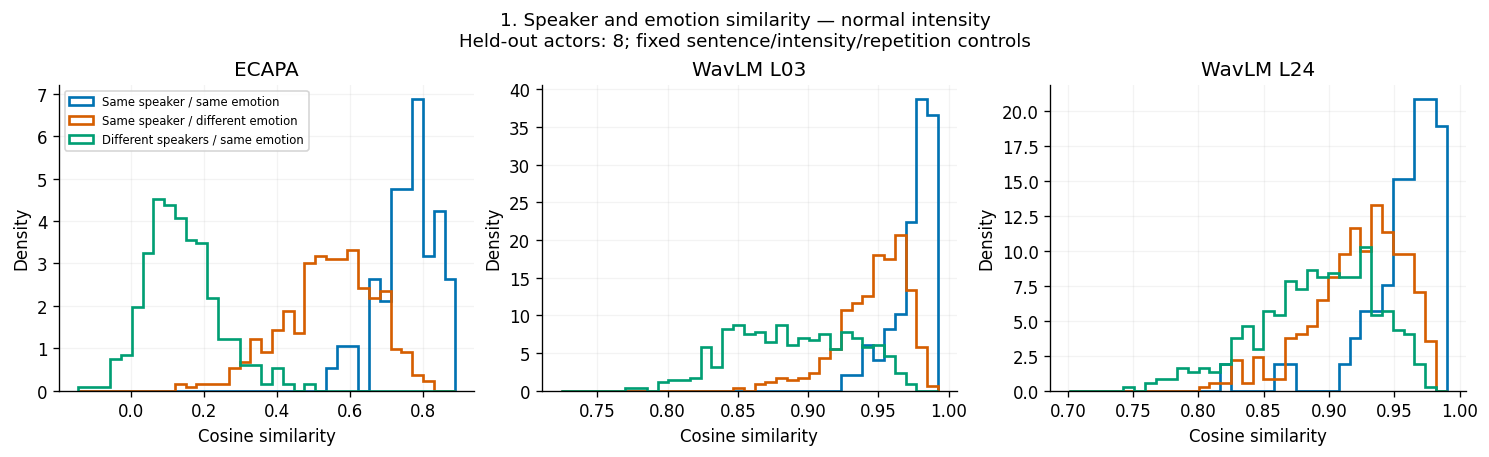

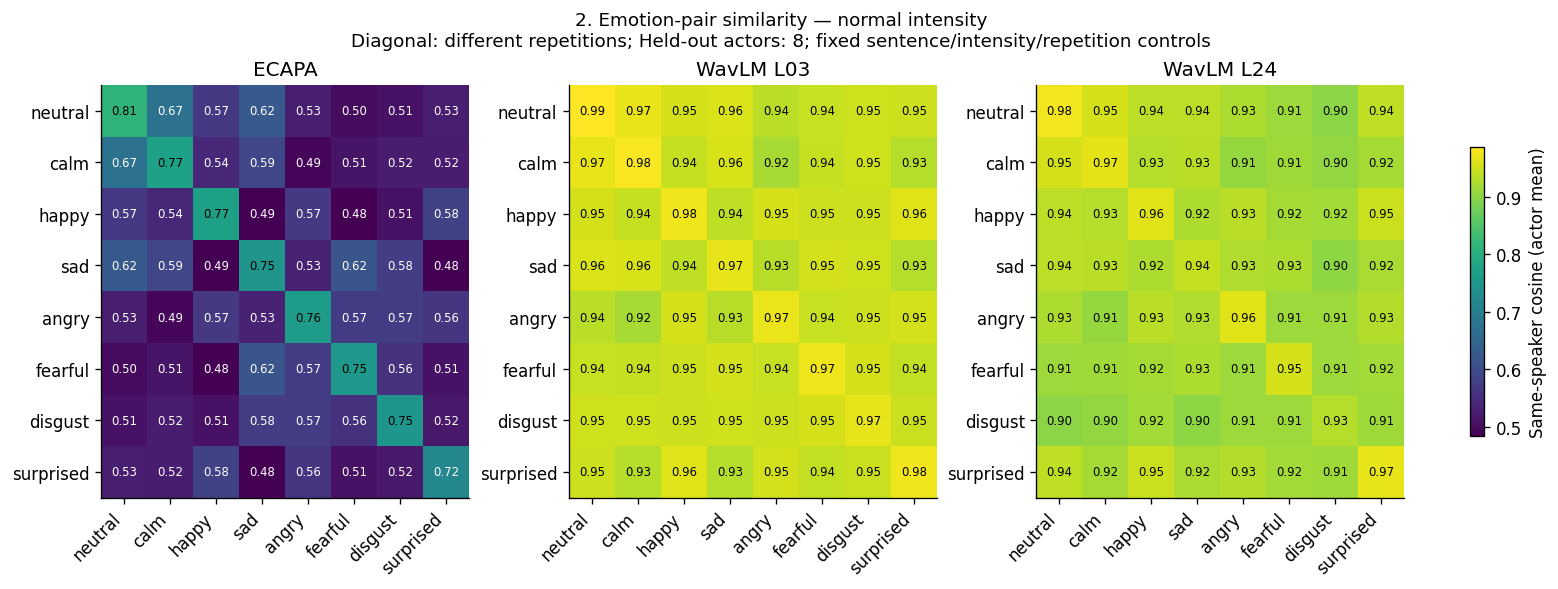

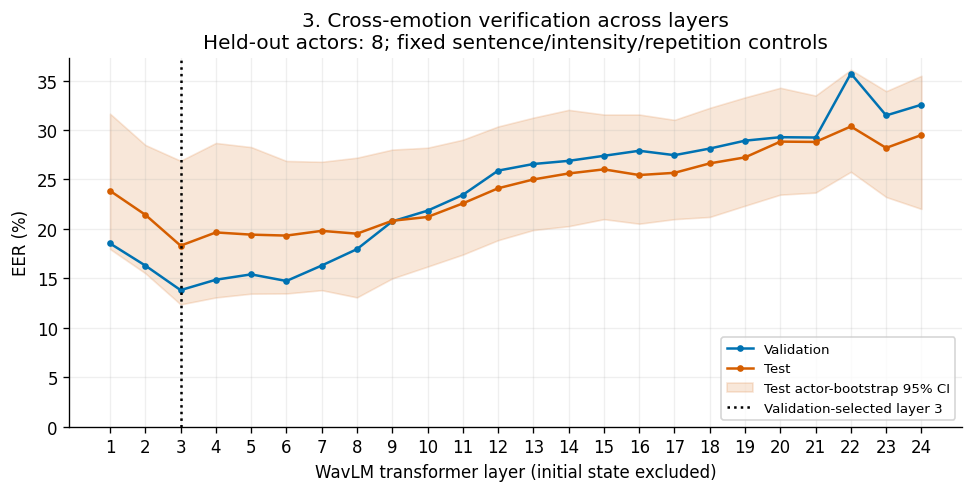

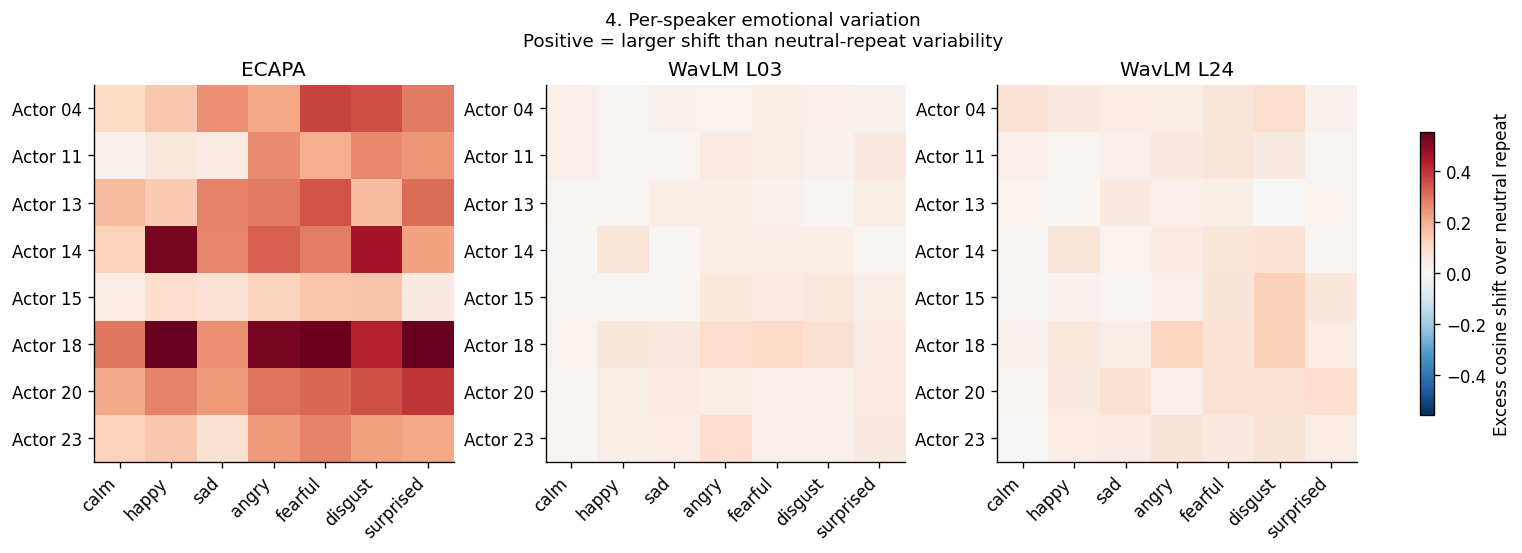

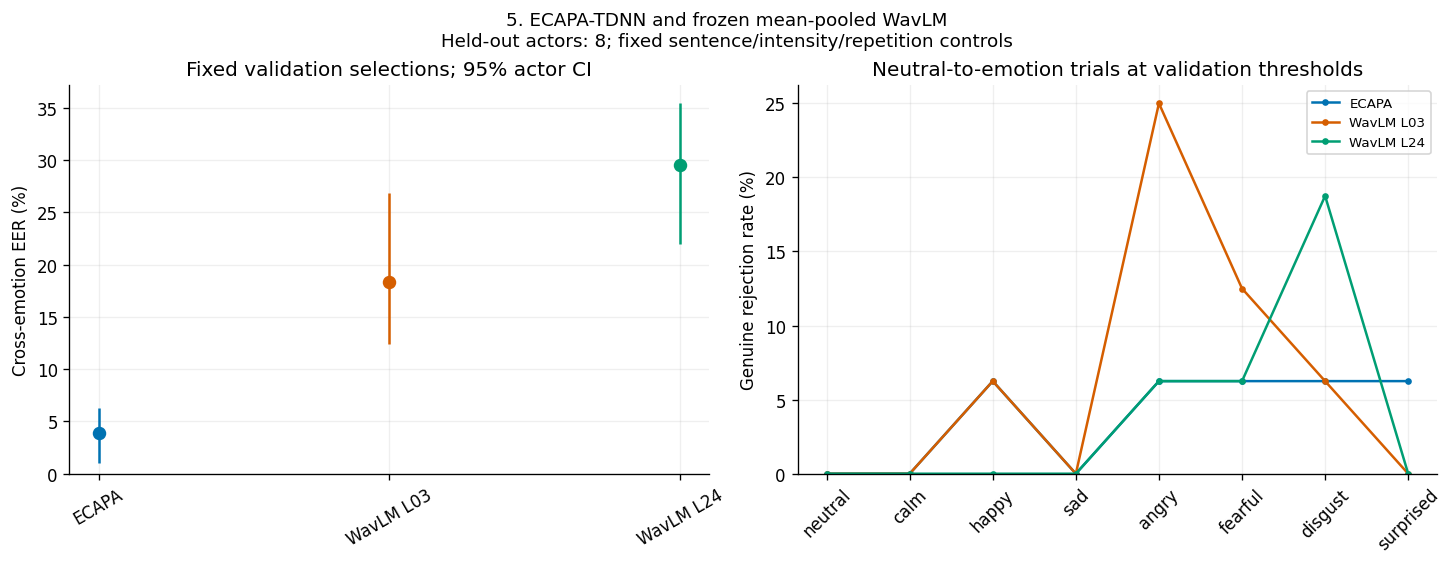

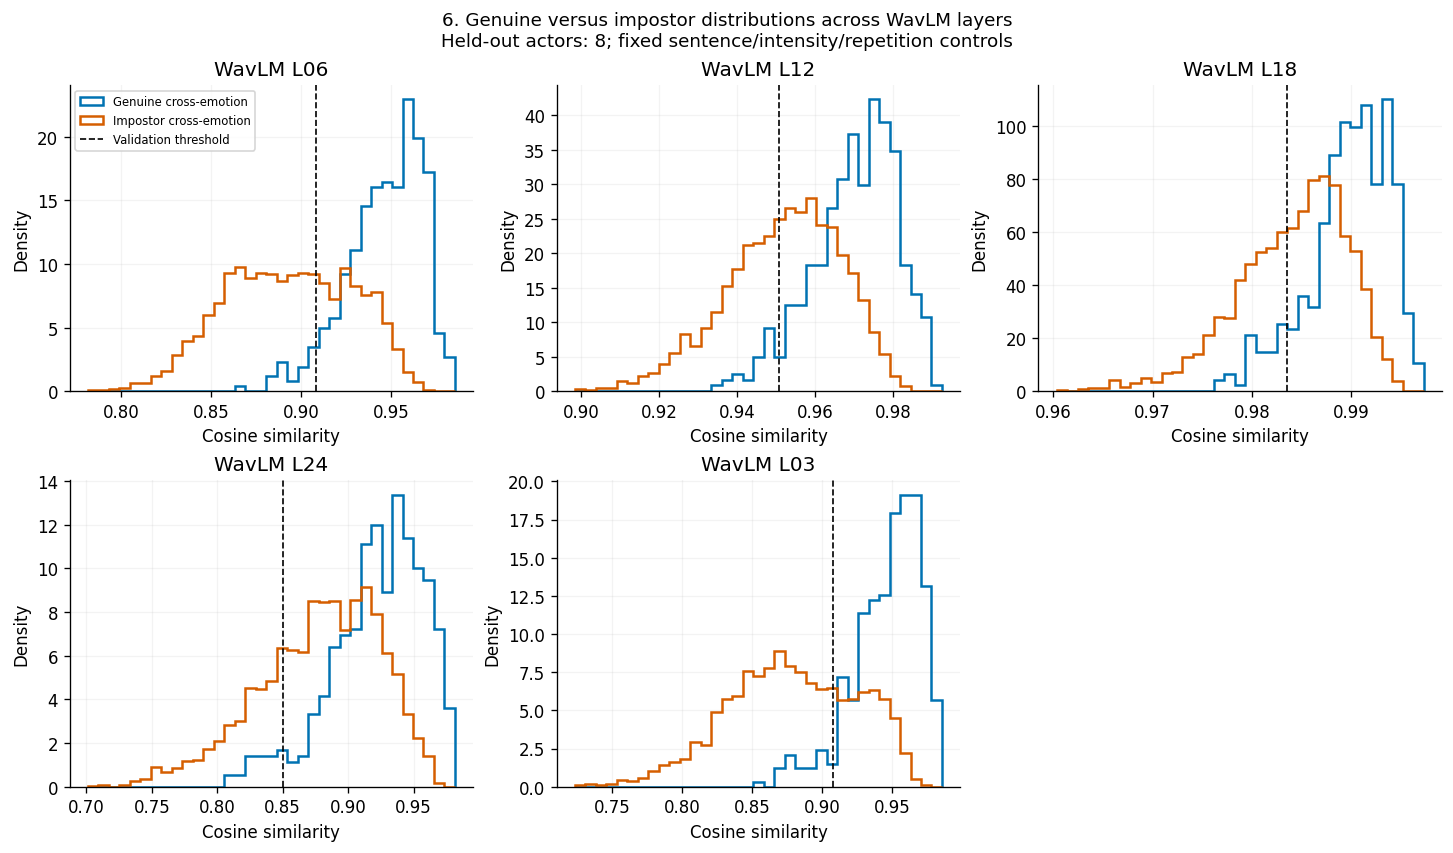

In [ ]:
make_figures(pairs, scores_by_rep, emotion_similarity, speaker_analysis, verification,
             selection, COMPARISON_REPS, thresholds, OUT_DIR / "figures")

## Audio examples

Inspect selected neutral-enrollment identification cases.


In [ ]:
if PLAY_AUDIO:
    interesting = identification[identification.split.eq("test") & identification.representation.eq(selection["wavlm_selected"])
                                 & identification.emotion.ne("neutral")].copy()
    interesting["margin"] = interesting.own_neutral_score - interesting.strongest_impostor_score
    for row in interesting.nsmallest(3, "margin").itertuples(index=False):
        query = manifest.set_index("uid").loc[row.uid]
        neutral = manifest[manifest.actor.eq(row.actor) & manifest.emotion_id.eq(1)
                           & manifest.sentence.eq(query.sentence) & manifest.repetition.ne(query.repetition)].iloc[0]
        display(Markdown(f"**Actor {row.actor:02d}, {row.emotion}; own-minus-impostor margin {row.margin:.3f}**"))
        display(Audio(str(query.path)))
        display(Audio(str(neutral.path)))

## Research report and exports

Write the measured results, configurations, and figures.


In [ ]:
def format_interval(low, high, scale=1, digits=3):
    if not np.isfinite(low) or not np.isfinite(high):
        return "CI unavailable (too few valid actor draws)"
    return f"95% actor CI [{scale * low:.{digits}f}, {scale * high:.{digits}f}]"

def generate_report(config, selection, validation_results, verification, contrasts, paired_comparisons,
                    speaker_analysis, emotion_effects, identification):
    chosen = selection["wavlm_selected"]
    intermediate = selection["wavlm_intermediate"]
    primary = verification[verification.split.eq("test") & verification.condition.eq("cross_emotion")].set_index("representation")
    test_speakers = speaker_analysis[speaker_analysis.split.eq("test")]
    lines = ["# Emotion-invariant speaker representations: measured results", "",
             f"Run `{config['created_utc']}`; mode **{config['mode']}**. "
             f"Actor counts: {len(config['actor_splits']['train'])} train, {len(config['actor_splits']['validation'])} validation, "
             f"{len(config['actor_splits']['test'])} held-out test. Models frozen; thresholds and layers chosen on validation only.", ""]
    if config["mode"] == "smoke":
        lines += ["**Smoke mode: pipeline check only. Two test actors cannot support reliable population inference.**", ""]
    lines += ["**1. Does emotional variation alter speaker representations?**", ""]
    for name in ("ECAPA", chosen):
        row = contrasts[contrasts.representation.eq(name) & contrasts.contrast.eq("same_minus_cross_cosine")].iloc[0]
        evidence = "passes the prespecified Holm-corrected 0.05 test" if row.significant_holm_005 else "does not pass the prespecified Holm-corrected 0.05 test"
        direction = "decreases" if row.mean_effect > 0 else "increases"
        lines.append(f"- {name}: cross-emotion mean cosine {direction} by {abs(row.mean_effect):.3f} relative to same-emotion repeats "
                     f"({format_interval(row.ci_low, row.ci_high)} for same-minus-cross; Holm p={row.p_holm:.4f}); this contrast {evidence}.")
    lines += ["", "**2. Which emotions produce the greatest changes?** Rankings below are descriptive, at normal intensity.", ""]
    for name in ("ECAPA", chosen):
        rows = test_speakers[test_speakers.representation.eq(name) & test_speakers.emotion.ne("neutral")]
        ranking = rows.groupby("emotion").excess_shift_over_neutral_repeat.mean().sort_values(ascending=False)
        largest = ", ".join(f"{emotion} ({value:.3f})" for emotion, value in ranking.head(3).items())
        row = contrasts[contrasts.representation.eq(name) & contrasts.contrast.eq("anger_minus_sadness_shift")].iloc[0]
        lines.append(f"- {name}: largest excess shifts over neutral repeats: {largest}. Anger-minus-sadness shift "
                     f"{row.mean_effect:.3f} ({format_interval(row.ci_low, row.ci_high)}; Holm p={row.p_holm:.4f}). "
                     f"{'Evidence of a difference under the prespecified test.' if row.significant_holm_005 else 'No corrected evidence of an anger–sadness difference.'}")
    val = validation_results.set_index("representation").loc[chosen]
    row = primary.loc[chosen]
    lines += ["", "**3. Which WavLM layers preserve identity most effectively?**",
              f"Validation selected **{chosen}**, with validation EER {100 * val.eer:.2f}%. Its held-out EER is "
              f"{100 * row.eer:.2f}% ({format_interval(row.eer_ci_low, row.eer_ci_high, 100, 2)} in %), AUC {row.roc_auc:.3f}, "
              f"FAR {100 * row.far:.2f}% and FRR {100 * row.frr:.2f}% at its saved validation threshold. "
              f"Genuine/impostor mean cosine: {row.same_speaker_cosine:.3f}/{row.different_speaker_cosine:.3f}; "
              f"separation d-prime {row.d_prime:.3f}. The full layer curve is descriptive; no test layer was selected.", "",
              "**4. How does WavLM compare with ECAPA-TDNN?**"]
    delta = paired_comparisons.set_index("comparison").loc["selected_wavlm_minus_ecapa"]
    ec = primary.loc["ECAPA"]
    lines += [f"ECAPA test EER {100 * ec.eer:.2f}% (AUC {ec.roc_auc:.3f}); selected WavLM minus ECAPA EER "
              f"{100 * delta.eer_difference:+.2f} percentage points ({format_interval(delta.ci_low, delta.ci_high, 100, 2)} in points). "
              "Negative favors WavLM. ECAPA has speaker-recognition supervision; the WavLM probe uses fixed mean pooling.", "",
              "**5. Are intermediate layers better than the final layer?**"]
    delta = paired_comparisons.set_index("comparison").loc["intermediate_minus_final"]
    if np.isfinite(delta.ci_high) and delta.ci_high < 0:
        conclusion = "The exploratory paired interval favors the selected intermediate layer."
    elif np.isfinite(delta.ci_low) and delta.ci_low > 0:
        conclusion = "The exploratory paired interval favors the final layer."
    else:
        conclusion = "The paired interval does not resolve a difference."
    lines += [f"Validation-selected intermediate **{intermediate}** minus layer 24: EER difference "
              f"{100 * delta.eer_difference:+.2f} percentage points ({format_interval(delta.ci_low, delta.ci_high, 100, 2)} in points). "
              f"{conclusion} These nominal intervals do not include layer-selection uncertainty.", "",
              "**6. Are findings consistent across speakers, and do errors imply identity confusion?**", ""]
    for name in ("ECAPA", chosen):
        rows = emotion_effects[emotion_effects.representation.eq(name) & emotion_effects.split.eq("test")]
        ids = identification[identification.representation.eq(name) & identification.split.eq("test") & identification.emotion.ne("neutral")]
        error = ids.groupby("actor").identification_error.mean().mean()
        lines.append(f"- {name}: cosine decreases for {int(rows.similarity_drop.gt(0).sum())}/{len(rows)} test actors; "
                     f"actor drops range {rows.similarity_drop.min():.3f} to {rows.similarity_drop.max():.3f}. "
                     f"Non-neutral closed-set neutral-enrollment identification error is {100 * error:.1f}% across "
                     f"{int(ids.n_enrolled_actors.iloc[0])} enrolled actors (ties counted as errors). "
                     "Consult per-emotion FRR/FAR and per-speaker plots; representation shifts alone are not misidentifications.")
    lines += ["", "**7. Implications for speaker-change detection (hypothesis, not measured here).**",
              "If emotion moves genuine scores across an operating threshold, a similarity-based change detector might produce false "
              "speaker changes. The current results motivate testing emotion-controlled continuous recordings with annotated boundaries. "
              "This study measures verification and embedding robustness, not boundary detection or diarization error.", "",
              "**Limits.** RAVDESS has acted emotions from 24 actors, two sentences and controlled recordings. "
              "Only the test actors support these held-out estimates; reused trials are dependent. Actor bootstrap intervals are "
              "approximate and conditional on this split/trial design and fixed validation choices. Sign-flip tests assume symmetric "
              "actor effects. The four prespecified tests use Holm correction; other rankings and intervals are exploratory. "
              "Pilot omits sentence 2 and strong intensity. Full mode still matches intensity and uses normal-only neutral contrasts. "
              "Do not generalize directly to spontaneous conversation, unseen languages, recording conditions or speaker-change detection."]
    return "\n".join(lines)

def publish_latest(output_dir, result_root):
    for source in Path(output_dir).rglob("*"):
        if source.is_file():
            relative = source.relative_to(output_dir)
            dest = Path(result_root) / relative
            dest.parent.mkdir(parents=True, exist_ok=True)
            temp = dest.with_name(dest.name + ".tmp")
            shutil.copy2(source, temp)
            temp.replace(dest)
    json_write(Path(result_root) / "latest_run.json", {"archive": str(output_dir), "completed": True})

In [ ]:
report = generate_report(config, selection, validation_results, verification, contrasts, paired_comparisons,
                         speaker_analysis, emotion_effects, identification)
(OUT_DIR / "scientific_report.md").write_text(report)
config["completed_utc"] = datetime.now(timezone.utc).isoformat()
json_write(OUT_DIR / "experiment_config.json", config)
required = ["emotion_similarity.csv", "layerwise_eer.csv", "speaker_emotion_analysis.csv", "model_comparison.csv",
            "experiment_config.json", "split_manifest.csv", "pair_manifest.csv", "model_threshold_selection.json",
            "validation_selection.csv", "scientific_report.md"]
assert all((OUT_DIR / name).is_file() for name in required)
assert len(list((OUT_DIR / "figures").glob("*.png"))) == 6
assert len(list((OUT_DIR / "figures").glob("*.pdf"))) == 6
publish_latest(OUT_DIR, RESULT_ROOT)
display(Markdown(report))
print("Saved latest results:", RESULT_ROOT)
print("Archived this run:", OUT_DIR)
print("Re-running with the same audio, revisions and inference configuration reuses feature caches.")

# Emotion-invariant speaker representations: measured results

Run `20261114T211142902790Z_pilot`; mode **pilot**. Actor counts: 8 train, 8 validation, 8 held-out test. Models frozen; thresholds and layers chosen on validation only.

**1. Does emotional variation alter speaker representations?**

- ECAPA: cross-emotion mean cosine decreases by 0.216 relative to same-emotion repeats (95% actor CI [0.184, 0.251] for same-minus-cross; Holm p=0.0312); this contrast passes the prespecified Holm-corrected 0.05 test.
- WavLM L03: cross-emotion mean cosine decreases by 0.029 relative to same-emotion repeats (95% actor CI [0.024, 0.033] for same-minus-cross; Holm p=0.0312); this contrast passes the prespecified Holm-corrected 0.05 test.

**2. Which emotions produce the greatest changes?** Rankings below are descriptive, at normal intensity.

- ECAPA: largest excess shifts over neutral repeats: fearful (0.312), disgust (0.303), angry (0.285). Anger-minus-sadness shift 0.097 (95% actor CI [0.031, 0.171]; Holm p=0.0469). Evidence of a difference under the prespecified test.
- WavLM L03: largest excess shifts over neutral repeats: angry (0.051), fearful (0.042), surprised (0.038). Anger-minus-sadness shift 0.022 (95% actor CI [0.005, 0.037]; Holm p=0.0625). No corrected evidence of an anger–sadness difference.

**3. Which WavLM layers preserve identity most effectively?**
Validation selected **WavLM L03**, with validation EER 13.81%. Its held-out EER is 18.30% (95% actor CI [12.36, 26.89] in %), AUC 0.907, FAR 29.75% and FRR 7.14% at its saved validation threshold. Genuine/impostor mean cosine: 0.946/0.879; separation d-prime 1.850. The full layer curve is descriptive; no test layer was selected.

**4. How does WavLM compare with ECAPA-TDNN?**
ECAPA test EER 3.89% (AUC 0.993); selected WavLM minus ECAPA EER +14.41 percentage points (95% actor CI [9.93, 22.54] in points). Negative favors WavLM. ECAPA has speaker-recognition supervision; the WavLM probe uses fixed mean pooling.

**5. Are intermediate layers better than the final layer?**
Validation-selected intermediate **WavLM L03** minus layer 24: EER difference -11.19 percentage points (95% actor CI [-17.53, -2.40] in points). The exploratory paired interval favors the selected intermediate layer. These nominal intervals do not include layer-selection uncertainty.

**6. Are findings consistent across speakers, and do errors imply identity confusion?**

- ECAPA: cosine decreases for 8/8 test actors; actor drops range 0.129 to 0.317. Non-neutral closed-set neutral-enrollment identification error is 5.4% across 8 enrolled actors (ties counted as errors). Consult per-emotion FRR/FAR and per-speaker plots; representation shifts alone are not misidentifications.
- WavLM L03: cosine decreases for 8/8 test actors; actor drops range 0.020 to 0.040. Non-neutral closed-set neutral-enrollment identification error is 26.8% across 8 enrolled actors (ties counted as errors). Consult per-emotion FRR/FAR and per-speaker plots; representation shifts alone are not misidentifications.

**7. Implications for speaker-change detection (hypothesis, not measured here).**
If emotion moves genuine scores across an operating threshold, a similarity-based change detector might produce false speaker changes. The current results motivate testing emotion-controlled continuous recordings with annotated boundaries. This study measures verification and embedding robustness, not boundary detection or diarization error.

**Limits.** RAVDESS has acted emotions from 24 actors, two sentences and controlled recordings. Only the test actors support these held-out estimates; reused trials are dependent. Actor bootstrap intervals are approximate and conditional on this split/trial design and fixed validation choices. Sign-flip tests assume symmetric actor effects. The four prespecified tests use Holm correction; other rankings and intervals are exploratory. Pilot omits sentence 2 and strong intensity. Full mode still matches intensity and uses normal-only neutral contrasts. Do not generalize directly to spontaneous conversation, unseen languages, recording conditions or speaker-change detection.

Saved latest results: /content/drive/MyDrive/RAVDESS/experiment_results
Archived this run: /content/drive/MyDrive/RAVDESS/experiment_results/runs/20261114T211142902790Z_pilot
Re-running with the same audio, revisions and inference configuration reuses feature caches.


## Saved artifacts

The experiment outputs contain verification tables, actor analyses, and figures.
